# Химический состав образцов керамики


Сравним, сколько Na₂O и Al₂O₃ содержится в основе (Body) и глазури (Glaze). Оба вещества измерены в массовых процентах. В CSV 88 строк, по две на каждый из 44 образцов.

[Четыре величины](#rv01) · [Зависимость](#dependence) · [Выборки и оценки](#sampling) · [Гипотеза](#hypothesis) · [Выводы](#resume)


В лабораторной работе использовался открытый датасет UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/583/chemical+composition+of+ceramic+samples Открытый репозиторий представляет нам кассификацию образцов древней китайской керамики - Longquan celadon на основе их химического состава на основе энергодисперсионной рентгеновской флуоресценции. Для изучения сырья и технологии обжига они отобрали 40 типичных осколков, относящихся к четырем культурным эпохам. В таблице представлены процентные содрежания таких соединений как: Na2O, MgO, Al2O3, SiO2, K2O, CaO, TiO2, Fe2O3, MnO, CuO, ZnO, PbO2, Rb2O, SrO, Y2O3, ZrO2, P2O5. Их содержание представлено в основах(body) и в глазури(glaze) остатков.

Цель исследования: провести статистический анализ химического состава образцов керамики Longquan celadon; исследовать особенности распредления компонентов в body и glaze; сравнить процентное содержание вещест в body и glaze в рамках 1 осататка керамики.

В рамках данной лабораторной работы мы будем подробно изучать 4 случайные величины: процентное содержание Na2O в body, процентное содержание Na2O в glaze, процентное содержание Al2O3 в body, процентное содержание Al2O3 в glaze. Параметры являются случайными величинами, так как их содержание можно узнать только на основе измерения - энергодисперсионной рентгеновской флуоресценции. Мы не можем знать заранее точное содержание изучаемых оксидов. А образец керамики мы выбиарем случайно. Поэтому мы можем изучать данные случайные величины прикладной математической статистикой.

## Оглавление

- [Почему рассматриваем данные как случайные величины](##почему-рассматриваем-данные-как-случайные-величины)


## Почему рассматриваем данные как случайные величины

Когда выбираем один образец, у него есть четыре числа, заранее эти числа нельзя. В исходном исследовании значения определили методом рентгенофлуоресцентного анализа. При выборе другого образца значения могут поменяться. Поэтому рассматриваем их как случайные величины.


In [1]:
<details>
<summary> Импорт библиотек и загрузка данных (нажми, чтобы развернуть)</summary>

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from itertools import combinations

df = pd.read_csv('Chemical Composion of Ceramic.csv')
body = df[df['Part'] == 'Body'].copy()
glaze = df[df['Part'] == 'Glaze'].copy()

body['Образец'] = body['Ceramic Name'].str.removesuffix('-b')
glaze['Образец'] = glaze['Ceramic Name'].str.removesuffix('-g')

paired = body.merge(glaze, on='Образец', suffixes=('_body', '_glaze'), validate='one_to_one')
assert len(paired) == len(body) == len(glaze)

data = paired.set_index('Образец')[['Na2O_body', 'Na2O_glaze', 'Al2O3_body', 'Al2O3_glaze']]
data.columns = ['Na₂O в основе', 'Na₂O в глазури', 'Al₂O₃ в основе', 'Al₂O₃ в глазури']
assert data.notna().all().all()
print(f'Строк в CSV: {len(df)}. Полных пар: {len(data)}. Пропусков в этих четырёх столбцах нет.')
data.head()
```

</details>


Строк в CSV: 88. Полных пар: 44. Пропусков в этих четырёх столбцах нет.


,Na₂O в основе,Na₂O в глазури,Al₂O₃ в основе,Al₂O₃ в глазури
Образец,,,,
FLQ-1,0.62,0.97,19.61,11.42
FLQ-2,0.57,1.46,21.19,12.96
FLQ-3,0.49,1.05,18.60,13.64
FLQ-4,0.89,0.14,18.01,12.42
FLQ-5,0.03,0.37,18.41,13.15


<a id="models"></a>
### Графики 

- Гистограмма показывает, какие значения встречаются чаще. На диаграмме размаха линия внутри прямоугольника — медиана. Отдельные точки показывают возможные выбросы по правилу $1{,}5\,IQR$, где $IQR=Q_3-Q_1$. Эти точки оставляем в данных.
- При стандартизации вычитаем среднее и делим на выборочное стандартное отклонение: $z=(x-\bar x)/s$. Получаем среднее около 0 и стандартное отклонение 1. Форма гистограммы сохраняется, меняется шкала.
- Нормальное распределение симметрично, его центр — среднее $\mu$, а разброс задаёт стандартное отклонение $\sigma$. Его плотность
  $$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).$$
  Если нормальная модель подходит, точки на Q–Q графике примерно ложатся на прямую. Критерий Шапиро — Уилка помогает проверить это численно. При $p<0{,}05$ отвергаем нормальность.

In [4]:
def describe_and_plot(values):
    summary = values.describe().rename(index={
        'count': 'Число значений', 'mean': 'Среднее', 'std': 'Стандартное отклонение',
        'min': 'Минимум', '25%': 'Первый квартиль', '50%': 'Медиана',
        '75%': 'Третий квартиль', 'max': 'Максимум',
    })
    summary['Дисперсия'] = values.var()
    summary['Асимметрия'] = values.skew()
    display(summary.round(3).to_frame(values.name))

    z = (values - values.mean()) / values.std()
    test = stats.shapiro(values)
    print(f'После стандартизации: среднее {z.mean():.2f}, стандартное отклонение {z.std():.2f}.')
    print(f'Шапиро — Уилк: W = {test.statistic:.4f}, p = {test.pvalue:.4f}.')

    fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), layout='constrained')
    hist, box, scaled, qq = axes.flat
    hist.hist(values, bins=10, edgecolor='white')
    hist.set(title='Гистограмма', xlabel='Доля, масс. %', ylabel='Число образцов')
    box.boxplot(values)
    box.set(title='Диаграмма размаха', ylabel='Доля, масс. %', xticks=[])
    scaled.hist(z, bins=10, edgecolor='white')
    scaled.set(title='После стандартизации', xlabel='z', ylabel='Число образцов')
    stats.probplot(values, dist='norm', plot=qq)
    qq.set(title='Q–Q график', xlabel='Квантили нормальной модели', ylabel='Доля, масс. %')
    fig.suptitle(values.name)
    plt.show()

<a id="rv01"></a>
## Random Variable 01 — Na₂O в основе

### Description

Доля оксида натрия в основе выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Na₂O в основе
Число значений,44.000
Среднее,0.397
Стандартное отклонение,0.211
Минимум,0.030
Первый квартиль,0.258
Медиана,0.370
Третий квартиль,0.552
Максимум,0.890
Дисперсия,0.045
Асимметрия,0.400


После стандартизации: среднее 0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9730, p = 0.3839.


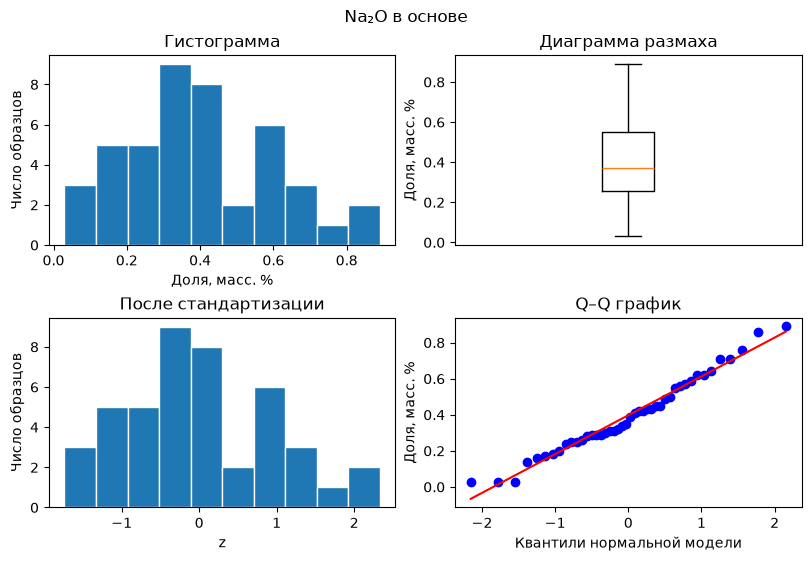

In [3]:
describe_and_plot(data['Na₂O в основе'])

Среднее 0,398 масс. %, медиана 0,370 масс. %. По тесту Шапиро — Уилка ($p=0{,}384$) нет оснований отвергать нормальную модель.

<a id="rv02"></a>
## Random Variable 02 — Na₂O в глазури

### Description

Доля оксида натрия в глазури выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Na₂O в глазури
Число значений,44.000
Среднее,0.546
Стандартное отклонение,0.436
Минимум,0.030
Первый квартиль,0.222
Медиана,0.375
Третий квартиль,0.722
Максимум,1.880
Дисперсия,0.190
Асимметрия,1.070


После стандартизации: среднее 0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.8975, p = 0.0009.


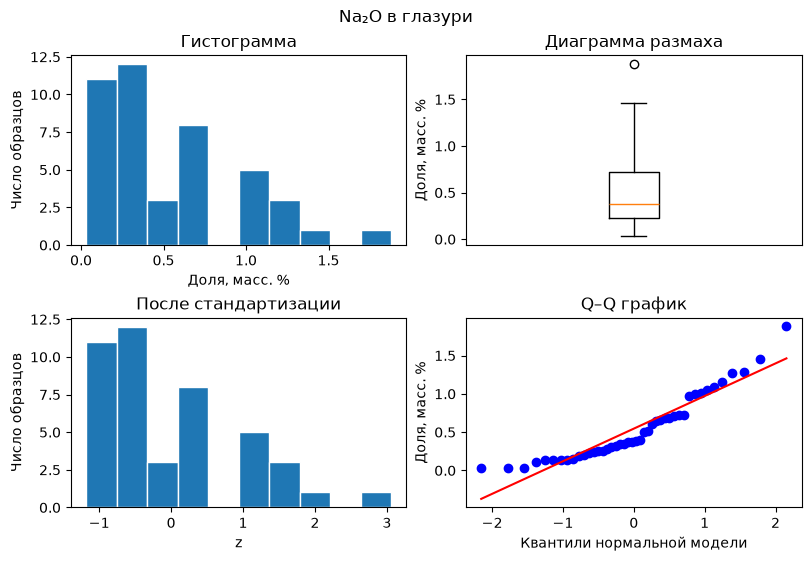

In [4]:
describe_and_plot(data['Na₂O в глазури'])

Среднее 0,546 масс. %, а медиана 0,375 масс. %. На гистограмме заметен правый хвост. При $p=0{,}0009$ отвергаем нормальную модель и пробуем две другие.

При логнормальной модели логарифмы значений должны быть нормальными. Все значения положительны, поэтому берём логарифм и снова применяем Шапиро — Уилка.

Ещё один вариант — гамма-распределение. Оно подходит для положительных значений и может иметь правый хвост. У него два параметра: $k$ задаёт форму, $\theta$ — масштаб. Среднее равно $k\theta$, дисперсия — $k\theta^2$. Плотность имеет вид
$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\qquad x>0.$$

Подбираем параметры по данным. Статистика $D$ показывает самое большое расстояние между функцией распределения модели и данными. Чтобы найти $p$, 1 999 раз создаём пробную выборку из модели и каждый раз заново подбираем параметры. Это параметрический бутстрэп. [Документация SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html)

Логнормальная модель: p = 0.0137


Гамма-модель: k = 1.4310, θ = 0.3815
D = 0.0754, p = 0.7605


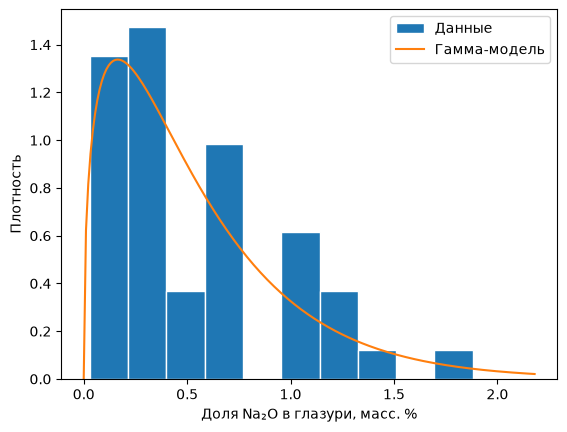

In [5]:
sodium_glaze = data['Na₂O в глазури'].to_numpy()
log_test = stats.shapiro(np.log(sodium_glaze))
print(f'Логнормальная модель: p = {log_test.pvalue:.4f}')

shape, location, scale = stats.gamma.fit(sodium_glaze, floc=0)
gamma_test = stats.goodness_of_fit(
    stats.gamma, sodium_glaze, known_params={'loc': 0},
    statistic='ks', n_mc_samples=1999, rng=42,
)
print(f'Гамма-модель: k = {shape:.4f}, θ = {scale:.4f}')
print(f'D = {gamma_test.statistic:.4f}, p = {gamma_test.pvalue:.4f}')

x = np.linspace(0, sodium_glaze.max() + 0.3, 200)
plt.hist(sodium_glaze, bins=10, density=True, edgecolor='white', label='Данные')
plt.plot(x, stats.gamma.pdf(x, shape, loc=location, scale=scale), label='Гамма-модель')
plt.xlabel('Доля Na₂O в глазури, масс. %')
plt.ylabel('Плотность')
plt.legend()
plt.show()

Для логнормальной модели $p=0{,}0137$, поэтому её отвергаем. Для гамма-модели $p=0{,}7605$. По этому тесту гамма-распределение можно использовать как приближение.

<a id="rv03"></a>
## Random Variable 03 — Al₂O₃ в основе

### Description

Доля оксида алюминия в основе выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Al₂O₃ в основе
Число значений,44.000
Среднее,21.812
Стандартное отклонение,2.301
Минимум,17.650
Первый квартиль,19.590
Медиана,21.835
Третий квартиль,23.310
Максимум,26.480
Дисперсия,5.293
Асимметрия,0.001


После стандартизации: среднее -0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9735, p = 0.4002.


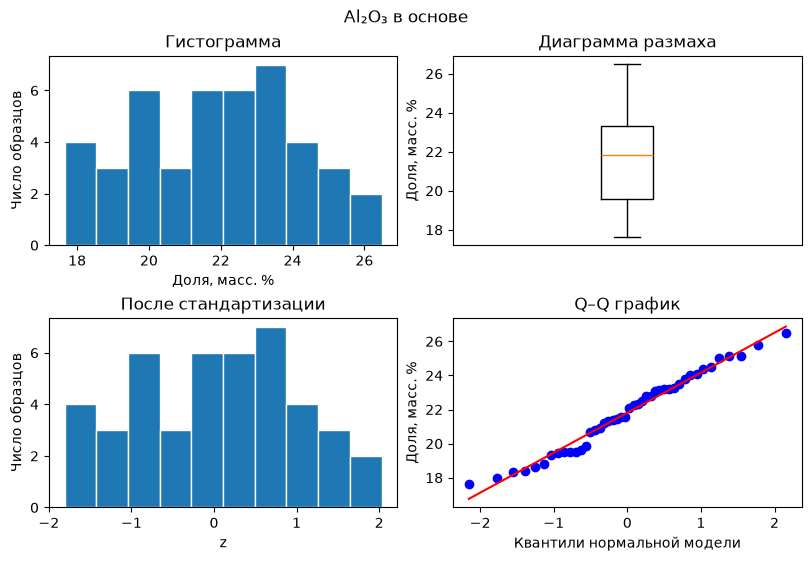

In [6]:
describe_and_plot(data['Al₂O₃ в основе'])

Среднее и медиана почти совпадают (21,812 и 21,835 масс. %). При $p=0{,}400$ нет оснований отвергать нормальную модель.

<a id="rv04"></a>
## Random Variable 04 — Al₂O₃ в глазури

### Description

Доля оксида алюминия в глазури выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Al₂O₃ в глазури
Число значений,44.000
Среднее,13.110
Стандартное отклонение,0.849
Минимум,11.300
Первый квартиль,12.708
Медиана,13.005
Третий квартиль,13.715
Максимум,14.760
Дисперсия,0.720
Асимметрия,-0.305


После стандартизации: среднее -0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9721, p = 0.3587.


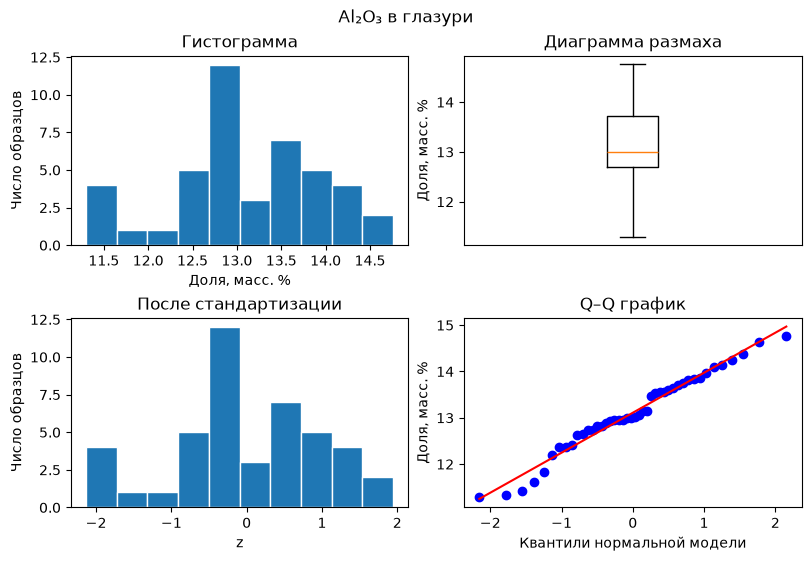

In [7]:
describe_and_plot(data['Al₂O₃ в глазури'])

Среднее 13,110 масс. %. Значения разбросаны меньше, чем в основе: стандартные отклонения 0,849 и 2,301 п.п. соответственно. При $p=0{,}359$ нет оснований отвергать нормальную модель.

<a id="dependence"></a>
### Зависимость

Диаграмм рассеяния: каждая точка — один образец. Коэффициент Пирсона ($r$) показывает, насколько заметна линейная связь. 

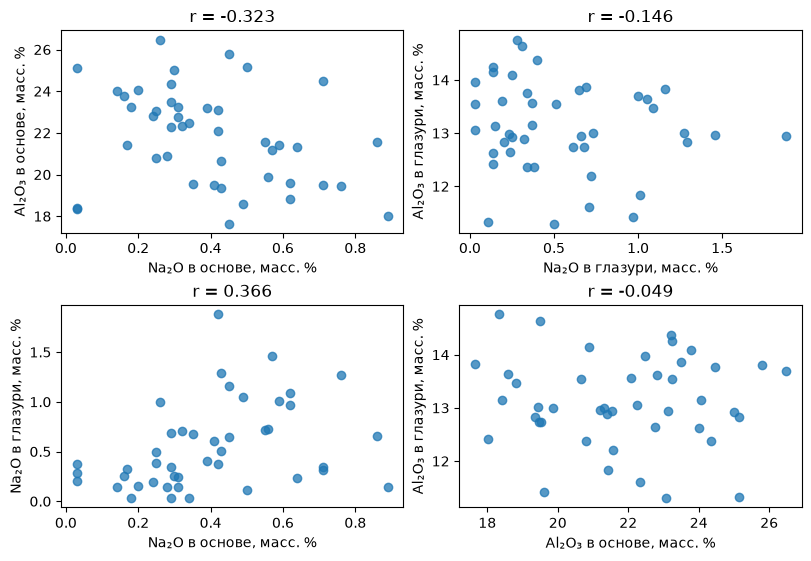

In [8]:
pairs_to_plot = [(0, 2), (1, 3), (0, 1), (2, 3)]
fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), layout='constrained')

for ax, (first, second) in zip(axes.flat, pairs_to_plot):
    x = data.iloc[:, first]
    y = data.iloc[:, second]
    ax.scatter(x, y, alpha=0.75)
    ax.set(xlabel=f'{x.name}, масс. %', ylabel=f'{y.name}, масс. %',
           title=f'r = {x.corr(y):.3f}')

plt.show()

Теперь проверим независимость для всех шести пар. Сначала считаем меру связи на исходных парах. Затем перемешиваем значения одной величины между образцами и снова считаем её. Если при перемешивании такая же или более сильная связь встречается редко, это аргумент против независимости.

В качестве меры используем квадрат дистанционной ковариации. Он сравнивает расстояния между наблюдениями и позволяет заметить связь, даже если она нелинейная. В коде сначала вычитаем из каждого расстояния среднее по его строке и столбцу, затем добавляем общее среднее. После этого перемножаем две матрицы поэлементно и берём среднее. 

In [9]:
def centered_distances(values):
    distances = np.abs(values[:, None] - values[None, :])
    row_means = distances.mean(axis=1, keepdims=True)
    column_means = distances.mean(axis=0)
    return distances - row_means - column_means + distances.mean()


rng = np.random.default_rng(301)
orders = [rng.permutation(len(data)) for _ in range(4999)]
results = []

for first, second in combinations(data.columns, 2):
    a = centered_distances(data[first].to_numpy())
    b = centered_distances(data[second].to_numpy())
    observed = (a * b).mean()

    at_least_as_large = 0
    for order in orders:
        shuffled = b[np.ix_(order, order)]
        if (a * shuffled).mean() >= observed - 1e-12:
            at_least_as_large += 1

    p = (at_least_as_large + 1) / (len(orders) + 1)
    results.append([first, second, data[first].corr(data[second]), p])

dependence = pd.DataFrame(results, columns=['Величина 1', 'Величина 2', 'r Пирсона', 'p'])

Делаем шесть проверок, поэтому учитываем, что маленькое $p$ может случайно встретиться хотя бы в одной. По методу Холма сортируем $p$ от меньшего к большему, умножаем на 6, 5 и так далее, а затем не даём скорректированным значениям уменьшаться. Сравниваем их с 0,05.

In [10]:
dependence = dependence.sort_values('p', ignore_index=True)
number_of_tests = len(dependence)
multipliers = range(number_of_tests, 0, -1)
adjusted = dependence['p'] * list(multipliers)
dependence['p с поправкой Холма'] = adjusted.cummax().clip(upper=1)
dependence.round(4)

,Величина 1,Величина 2,r Пирсона,p,p с поправкой Холма
0,Na₂O в основе,Na₂O в глазури,0.3663,0.0030,0.018
1,Na₂O в основе,Al₂O₃ в основе,-0.3228,0.0064,0.032
2,Na₂O в глазури,Al₂O₃ в основе,-0.2942,0.0150,0.060
3,Na₂O в глазури,Al₂O₃ в глазури,-0.1463,0.5118,1.000
4,Na₂O в основе,Al₂O₃ в глазури,-0.1450,0.8028,1.000
5,Al₂O₃ в основе,Al₂O₃ в глазури,-0.0486,0.8740,1.000


Независимость отвергается для двух пар: Na₂O в основе и глазури ($p=0{,}018$) и Na₂O с Al₂O₃ внутри основы ($p=0{,}032$). Для остальных пар данных недостаточно для вывода о зависимости. Перестановочный тест предполагает, что при независимости строки можно свободно перемешивать. Если группы образцов различаются по составу, они тоже могут влиять на результат.

<a id="sampling"></a>
### Выборки и оценки

Проверим, насколько хорошо небольшая выборка описывает все 44 образца. Для каждой схемы берём 20 идентификаторов. Каждый раз вместе берём все четыре измерения образца.

- **С возвращением** один и тот же образец может попасть в выборку несколько раз.
- **Без возвращения** один образец может попасть только один раз.

Сравниваем среднее и дисперсию выборки со значениями по полному CSV. В дисперсии полного набора делим на $N=44$. В выборочной дисперсии делим на $n-1$. Для отбора без возвращения дополнительно умножаем выборочную дисперсию на $(N-1)/N$, чтобы она в среднем оценивала дисперсию с делителем $N$.

In [11]:
N = len(data)
full_mean = data.mean()
full_variance = data.var(ddof=0)
methods = {True: 'С возвращением', False: 'Без возвращения'}
rng = np.random.default_rng(91)

comparison = pd.DataFrame({'Среднее по CSV': full_mean, 'Дисперсия по CSV': full_variance})

for replace, method in methods.items():
    indices = rng.choice(N, size=20, replace=replace)
    sample = data.iloc[indices]
    variance = sample.var(ddof=1)
    if not replace:
        variance *= (N - 1) / N

    print(f'{method}: {sample.index.nunique()} разных образцов из 20.')
    comparison[f'Среднее · {method.lower()}'] = sample.mean()
    comparison[f'Дисперсия · {method.lower()}'] = variance

display(comparison.filter(like='Среднее').round(4))
display(comparison.filter(like='Дисперсия').round(4))

С возвращением: 13 разных образцов из 20.
Без возвращения: 20 разных образцов из 20.


,Среднее по CSV,Среднее · с возвращением,Среднее · без возвращения
Na₂O в основе,0.3975,0.377,0.4160
Na₂O в глазури,0.5459,0.637,0.5255
Al₂O₃ в основе,21.8120,21.622,21.5340
Al₂O₃ в глазури,13.1098,13.167,12.8440


,Дисперсия по CSV,Дисперсия · с возвращением,Дисперсия · без возвращения
Na₂O в основе,0.0437,0.0421,0.0427
Na₂O в глазури,0.1858,0.1315,0.1518
Al₂O₃ в основе,5.1730,5.8383,6.2490
Al₂O₃ в глазури,0.7038,0.8985,0.7855


### Состоятельность оценок

Состоятельность означает, что с ростом выборки оценка с большой вероятностью оказывается близка к нужному значению. При отборе с возвращением это следует из закона больших чисел. Среднее значений и среднее их квадратов приближаются к значениям по всему CSV, а через них считается выборочная дисперсия. Без возвращения из этого файла можно взять максимум 44 образца. Тогда вся таблица попадёт в выборку и ошибки исчезнут.

Чтобы увидеть это на данных, для каждого размера делаем 2 000 повторов. Считаем RMSE: возводим ошибки в квадрат, усредняем и берём корень. Чем ниже линия, тем меньше ошибка.

In [12]:
def rmse(estimates, target):
    return np.sqrt(((estimates - target) ** 2).mean(axis=0))


rng = np.random.default_rng(2026)
sizes = [5, 10, 20, 30, N]
repeats = 2000
values = data.to_numpy()
errors = {}

for replace, method in methods.items():
    mean_errors = []
    variance_errors = []
    for n in sizes:
        if replace:
            indices = rng.integers(N, size=(repeats, n))
        else:
            indices = np.array([rng.choice(N, size=n, replace=False) for _ in range(repeats)])

        samples = values[indices]
        sample_means = samples.mean(axis=1)
        sample_variances = samples.var(axis=1, ddof=1)
        if not replace:
            sample_variances *= (N - 1) / N

        mean_errors.append(rmse(sample_means, full_mean.to_numpy()))
        variance_errors.append(rmse(sample_variances, full_variance.to_numpy()))

    errors[method] = np.array(mean_errors), np.array(variance_errors)

assert np.allclose(errors['Без возвращения'][0][-1], 0)
assert np.allclose(errors['Без возвращения'][1][-1], 0)

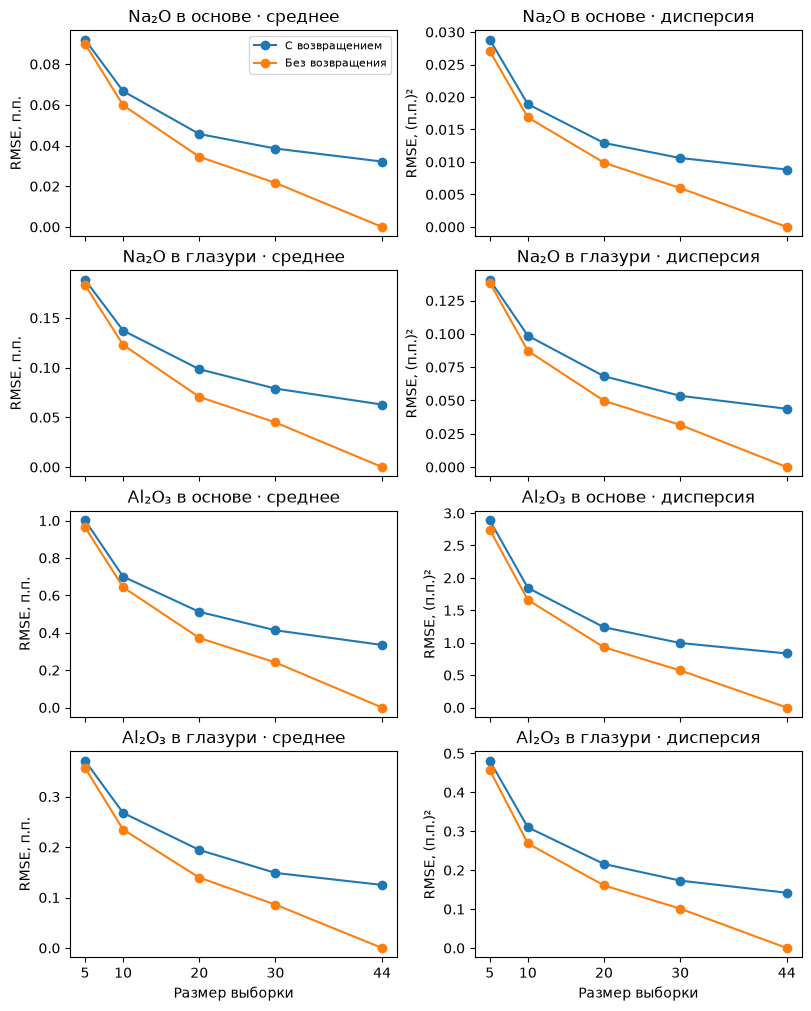

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(8, 10), layout='constrained', sharex=True)

for i, name in enumerate(data.columns):
    for method, (mean_errors, variance_errors) in errors.items():
        axes[i, 0].plot(sizes, mean_errors[:, i], 'o-', label=method)
        axes[i, 1].plot(sizes, variance_errors[:, i], 'o-', label=method)
    axes[i, 0].set(title=f'{name} · среднее', ylabel='RMSE, п.п.')
    axes[i, 1].set(title=f'{name} · дисперсия', ylabel='RMSE, (п.п.)²')

axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set(xlabel='Размер выборки', xticks=sizes)

plt.show()

На графиках видно, что ошибки уменьшаются с ростом выборки. Для среднего теория даёт простое сравнение: при отборе без возвращения дисперсия оценки уменьшается в $(N-n)/(N-1)$ раза. При $n=20$ RMSE среднего должен составить примерно 75% от ошибки при отборе с возвращением. В нашем опыте вышло от 71% до 75% для четырёх величин.

<a id="hypothesis"></a>
### Гипотеза про Na₂O

**Вопрос.** Отличается ли средняя доля Na₂O в глазури и в основе?

- $H_0$. Средняя разность «глазурь минус основа» равна нулю.
- $H_1$. Средняя разность отличается от нуля.

Измерения сделаны на одних и тех же образцах, поэтому используем **парный t-тест**. Он работает с разностями внутри каждой пары. Проверим их на нормальность и будем считать разности разных образцов независимыми. Уровень значимости — 0,05. 

In [14]:
sodium_body = data['Na₂O в основе']
sodium_glaze = data['Na₂O в глазури']
difference = sodium_glaze - sodium_body

normality = stats.shapiro(difference)
test = stats.ttest_rel(sodium_glaze, sodium_body)
interval = test.confidence_interval(confidence_level=0.95)

print(f'Шапиро — Уилк для разностей: p = {normality.pvalue:.4f}')
print(f'Средняя разность: {difference.mean():.3f} п.п.')
print(f'Парный t-тест: t = {test.statistic:.3f}, p = {test.pvalue:.4f}')
print(f'95%-й доверительный интервал: от {interval.low:.3f} до {interval.high:.3f} п.п.')

Шапиро — Уилк для разностей: p = 0.2756
Средняя разность: 0.148 п.п.
Парный t-тест: t = 2.407, p = 0.0205
95%-й доверительный интервал: от 0.024 до 0.273 п.п.


Для разностей $p=0{,}276$, поэтому тест Шапиро — Уилка не отвергает нормальность. Парный t-тест даёт $p=0{,}0205$. Отвергаем $H_0$ на уровне 0,05. В этих данных доля Na₂O в глазури в среднем выше на 0,148 процентного пункта.

<a id="resume"></a>
### Общие выводы

1. Для Na₂O в основе и Al₂O₃ в обеих частях можно использовать нормальную модель как приближение. Для Na₂O в глазури подошла гамма-модель.
2. Связь обнаружилась между долями Na₂O в основе и глазури и между двумя оксидами внутри основы.
3. Чем больше выборка, тем точнее мы оцениваем среднее и дисперсию. При отборе без возвращения среднее обычно оценивается точнее при том же размере выборки.
4. По 44 парам доля Na₂O в глазури оказалась в среднем выше, чем в основе. Эти образцы были заранее отобраны составителями набора, поэтому вывод про всю историческую керамику из них сделать трудно.

### table

| id | notebook_link | comment |
|---|---|---|
| EDA | [1](#rv01), [2](#rv02), [3](#rv03), [4](#rv04) | | Графики и статистики четырёх величин |
| Distribution | [Модели](#models) | | Стандартизация и проверка распределений |
| Independence | [Зависимость](#dependence) | | Пирсон и перестановочный тест |
| Estimations | [Выборки и оценки](#sampling) | | Две схемы отбора, ошибки оценок |
| Hypothesis | [Гипотеза](#hypothesis) | | Парный t-тест |
| Resume | [Выводы](#resume) | | Итоги |